# I. Data Exploration and Preprocessing


**Step 1:** Import the needed libraries

In [88]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import hashlib


from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split


**Step 2:** Import the labels dataset

In [89]:
labels = pd.read_csv("data/labels.csv")

In [90]:
labels.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   filename     60000 non-null  str  
 1   class_id     60000 non-null  str  
 2   description  60000 non-null  str  
dtypes: str(3)
memory usage: 1.4 MB


**Step 3:** Check for missing values

In [91]:
labels.isnull().sum()

filename       0
class_id       0
description    0
dtype: int64

The dataset has no missing values

**Step 4:** Check first five rows of the labels dataset

In [92]:
labels.head()

,filename,class_id,description
0,image_000001.JPEG,n03042490,cliff dwelling
1,image_000002.JPEG,n02793495,barn
2,image_000003.JPEG,n02793495,barn
3,image_000004.JPEG,n02793495,barn
4,image_000005.JPEG,n02793495,barn


**Step 5:** Encode ``class_id`` labels

In [93]:
label_encoder = LabelEncoder()

labels['encoded_id'] = label_encoder.fit_transform(labels['class_id'])

In [94]:
labels.head()

,filename,class_id,description,encoded_id
0,image_000001.JPEG,n03042490,cliff dwelling,91
1,image_000002.JPEG,n02793495,barn,66
2,image_000003.JPEG,n02793495,barn,66
3,image_000004.JPEG,n02793495,barn,66
4,image_000005.JPEG,n02793495,barn,66


All the labels are now encoded

**Step 6:** Check how many unique descriptions exist for each ``encoded_id``

In [95]:
description_per_id = labels.groupby('encoded_id')['description'].nunique()
description_per_id

encoded_id
0      1
1      1
2      1
3      1
4      1
      ..
195    1
196    1
197    1
198    1
199    1
Name: description, Length: 200, dtype: int64

If any class has more than 1 description associated with it, there is an inconsistency in the text metadata

In [96]:
inconsistencies = description_per_id[description_per_id >1]
print('Inconsistencies found: ', len(inconsistencies))

Inconsistencies found:  0


No class has more than one description associated with it, so no inconsistencies in the data were found so far.

**Step 7:** Check class distribution

In [97]:
labels['description'].nunique()

200

In this dataset there are 200 different classes

In [98]:
class_counts = labels['description'].value_counts()

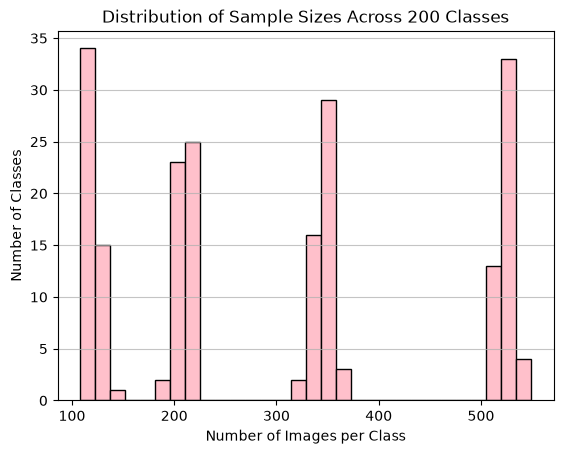

In [99]:
plt.hist(class_counts.values, bins=30, color='pink', edgecolor='black')
plt.title('Distribution of Sample Sizes Across 200 Classes')
plt.xlabel('Number of Images per Class')
plt.ylabel('Number of Classes')
plt.grid(axis='y', alpha=0.75)
plt.show()

**Step 8:** Check image dimensions

All images should be 64 x 64 pixels and RGB

In [100]:
dimensions = set()
modes = set()
images_files = os.path.join('data', 'images')

for fname in labels['filename']:
    img_path = os.path.join(images_files, fname)
    with Image.open(img_path) as img:
        dimensions.add(img.size)
        modes.add(img.mode)

print(f"Unique dimensions found: {dimensions}")
print(f"Unique color modes found: {modes}")

Unique dimensions found: {(64, 64)}
Unique color modes found: {'RGB'}


All images of the dataset are in the correct format, 64 x 64 pixels.
However, there are some images in 'L' mode instead of 'RGB'

**Step 9:** Convert from 'L' mode to the expected 'RGB' mode

In [101]:
for fname in labels['filename']:
    img_path = os.path.join(images_files, fname)
    with Image.open(img_path) as img:
        if img.mode == 'L':
            img = img.convert('RGB')
            img.save(img_path)

**Step 10:** Check if now all images have the right dimensions and mode

In [102]:
dimensions = set()
modes = set()
images_files = os.path.join('data', 'images')

for fname in labels['filename']:
    img_path = os.path.join(images_files, fname)
    with Image.open(img_path) as img:
        dimensions.add(img.size)
        modes.add(img.mode)

print(f"Unique dimensions found: {dimensions}")
print(f"Unique color modes found: {modes}")

Unique dimensions found: {(64, 64)}
Unique color modes found: {'RGB'}


Now, all images have the right dimensions and are in the right mode.

**Step 11:** Check if duplicate files are mapped to different classes.

Create a function that turns raw byte contents of an image into an MD5 hash (unique 32-character digital signature)

In [103]:
def turn_into_hash(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

Apply this function to every image in the dataset

In [104]:
labels['hash'] = labels['filename'].apply(lambda x: turn_into_hash(os.path.join(images_files, x)))

Check for duplicates

In [105]:
duplicates = labels.groupby('hash').filter(lambda x: x['class_id'].nunique() >1)
len(duplicates)

12

There are 12 images duplicated in our dataset associated with different classes.
Since 12 observations are a small portion of our dataset, these observations will be dropped.

In [106]:
duplicates_idx = duplicates.index

labels_cleaned = labels.drop(duplicates_idx).reset_index(drop=True)

print('Number of rows with duplicates: ', len(labels))
print('Number of rows after removing duplicates: ', len(labels_cleaned))

Number of rows with duplicates:  60000
Number of rows after removing duplicates:  59988


**Step 12:** Split data into train, validation and test

In [109]:
train, temp = train_test_split(labels_cleaned, test_size=0.30, random_state=42, 
                               stratify=labels_cleaned['encoded_id'])

validation, test = train_test_split(temp, test_size=0.50, random_state=42, 
                                    stratify=temp['encoded_id'])